# 01 — Data Understanding, Cleaning, and Preprocessing

## 1. Introduction and Objective

In this individual course project for **ES 335: Machine Learning**, I investigate and compare three distinct movie recommendation approaches: Bayesian Popularity, TF-IDF Content-Based Filtering, and Multi-Hot Genre Hybridization.

Before building any recommendation models, I need a clean, consistent, and well-structured movie dataset. Raw movie datasets collected from the web cannot be used directly because:
1. **Incompatible Identifiers**: Different platforms use different IDs. For example, MovieLens assigns its own `movieId`, while The Movie Database uses `tmdbId`.
2. **Missing Information**: Several movies lack plot summaries, release dates, or valid IDs.
3. **Complex Formats**: Attributes like movie genres are stored as text strings representing lists of dictionaries rather than clean lists.
4. **Catalogue Size**: The raw dataset contains over 45,000 titles spanning more than a century. To keep the project focused and relevant, I restrict the catalogue to modern movies released from **2010 onward**.

### Objective of this Notebook
In this notebook, I:
- Load and inspect raw data from MovieLens and The Movie Database (TMDB).
- Examine the relationships between movie metadata, identifier mappings, and user ratings.
- Perform exploratory data analysis with visual plots showing rating distributions, release years, vote counts, and genre frequencies.
- Clean invalid identifiers, remove duplicate entries, and handle missing values.
- Compute global rating statistics (vote count and average rating) for each movie.
- Save the final processed catalogue as `dataset/processed/movies_clean.csv` (12,794 movies).

This clean dataset directly feeds into my next three notebooks:
- **Notebook 02**: Popularity-based recommender using Bayesian weighted ratings.
- **Notebook 03**: Content-based recommender using TF-IDF on plot summaries.
- **Notebook 04**: Genre-based hybrid recommender blending multi-hot genre vectors with movie quality scores.


## 2. Data Understanding and Sources

For this project, I use **The Movies Dataset** (curated by Rounak Banik on Kaggle), which brings together data from GroupLens Research (MovieLens) and The Movie Database (TMDB) API.

### Datasets Used in MovieMatch

| Dataset File | Original Source | Records | What One Row Represents | Key Columns | Role in MovieMatch |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **`movies_metadata.csv`** | TMDB API | ~45,466 | One movie or feature film | `id`, `title`, `overview`, `release_date`, `genres`, `poster_path` | Provides movie titles, plot summaries for TF-IDF, genres, and poster image links. |
| **`links.csv` / `links_small.csv`** | MovieLens (GroupLens) | ~45,843 / 9,125 | Identifier mapping for one movie | `movieId`, `imdbId`, `tmdbId` | Serves as the relational bridge linking MovieLens `movieId` to TMDB `tmdbId`. |
| **`ratings.csv` / `ratings_small.csv`** | MovieLens (GroupLens) | ~26M / 100k | One rating given by one user to one movie | `userId`, `movieId`, `rating`, `timestamp` | Provides ground-truth user preferences (0.5 to 5.0 stars) for calculating movie popularity and evaluating models. |

### How the Datasets Connect to One Another
The three datasets form a clear relational chain:
- A user rates a movie identified by `movieId` in `ratings.csv`.
- `links.csv` maps that `movieId` to its corresponding `tmdbId`.
- `movies_metadata.csv` uses `id` (which matches `tmdbId`) to provide the movie's title, genres, and plot overview.

```
┌───────────────────────┐           ┌───────────────────────┐           ┌───────────────────────┐
│     ratings.csv       │           │       links.csv       │           │  movies_metadata.csv  │
├───────────────────────┤           ├───────────────────────┤           ├───────────────────────┤
│ userId                │           │ movieId               │           │ id (TMDB ID)          │
│ movieId  ─────────────┼──────────►│ movieId               │           │ title                 │
│ rating                │           │ tmdbId   ─────────────┼──────────►│ overview              │
│ timestamp             │           │ imdbId                │           │ genres                │
└───────────────────────┘           └───────────────────────┘           └───────────────────────┘
```

### Known Data Limitations
1. **Missing plot descriptions**: Roughly 2% of movies lack an overview. I impute these with empty strings so TF-IDF does not fail.
2. **Stringified JSON attributes**: Genres are stored as raw text (e.g. `'[{"id": 28, "name": "Action"}]'`), which requires parsing.
3. **Disparate timeframes**: The full ratings file covers ratings up to 2017, meaning very recent films are not present.
4. **Duplicate mappings**: A small number of TMDB IDs map to multiple MovieLens entries (different cuts or re-releases), which I consolidate.


## 3. Importing Libraries and Loading Data

I import standard Python data science libraries:
- `pandas` for tabular data manipulation and joins.
- `numpy` for numeric array computations.
- `matplotlib.pyplot` for creating exploratory plots.
- `ast` and `json` for parsing stringified genre lists.
- `pathlib.Path` for clean, cross-platform file path management.


In [1]:
import os
import ast
import json
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dynamic path resolution supporting both local repo execution and Google Colab
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "Notebooks" else NOTEBOOK_DIR

if Path("/content/drive/MyDrive/MovieMatch").exists():
    RAW_DATA_DIR = Path("/content/drive/MyDrive/MovieMatch")
elif (PROJECT_ROOT / "dataset" / "raw").exists():
    RAW_DATA_DIR = PROJECT_ROOT / "dataset" / "raw"
else:
    RAW_DATA_DIR = PROJECT_ROOT

PROCESSED_DATA_DIR = PROJECT_ROOT / "dataset" / "processed"
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data path: {RAW_DATA_DIR}")
print(f"Processed output path: {PROCESSED_DATA_DIR}")


Project root: /home/ashwin-kurup/ML_Couse_Project/MovieMatch
Raw data path: /home/ashwin-kurup/ML_Couse_Project/MovieMatch/dataset/raw
Processed output path: /home/ashwin-kurup/ML_Couse_Project/MovieMatch/dataset/processed


### Explanation
The code above detects where the notebook is running (locally or on Google Colab) and sets up the paths automatically. This ensures the notebook runs cleanly on any computer without manual path edits.


## 4. Exploratory Data Analysis (EDA)

Now I explore the raw datasets to understand their sizes, inspect sample rows, and create four visualizations:
1. **Rating Score Distribution**: To examine how users distribute their scores between 0.5 and 5.0 stars.
2. **Movie Release Year Distribution**: To see how many modern movies (2010+) are available per year.
3. **Movie Vote Count Distribution**: To observe the long-tail popularity curve in ratings.
4. **Movie Genre Frequency Distribution**: To understand which genres appear most frequently across the catalogue.


In [2]:
# Locate ratings and metadata files
ratings_path = RAW_DATA_DIR / "ratings.csv"
if not ratings_path.exists():
    ratings_path = RAW_DATA_DIR / "ratings_small.csv"

metadata_path = RAW_DATA_DIR / "movies_metadata.csv"
links_path = RAW_DATA_DIR / "links.csv"
if not links_path.exists():
    links_path = RAW_DATA_DIR / "links_small.csv"

# Load samples to inspect data structures
ratings_df = pd.read_csv(ratings_path)
metadata_df = pd.read_csv(
    metadata_path,
    usecols=["id", "title", "release_date", "genres", "overview"],
    low_memory=False
)
links_df = pd.read_csv(links_path)

print(f"Loaded {len(ratings_df):,} ratings from {ratings_path.name}")
print(f"Loaded {len(metadata_df):,} raw metadata records from {metadata_path.name}")
print(f"Loaded {len(links_df):,} ID mappings from {links_path.name}")

print("\nSample ratings:")
display(ratings_df.head(3))


Loaded 100,004 ratings from ratings_small.csv
Loaded 45,466 raw metadata records from movies_metadata.csv
Loaded 45,843 ID mappings from links.csv

Sample ratings:


,userId,movieId,rating,timestamp
0,1,31,2.5,1260759144
1,1,1029,3.0,1260759179
2,1,1061,3.0,1260759182


### EDA Plot 1: User Rating Score Distribution
Let us look at how users rate movies on the 0.5 to 5.0 star scale.


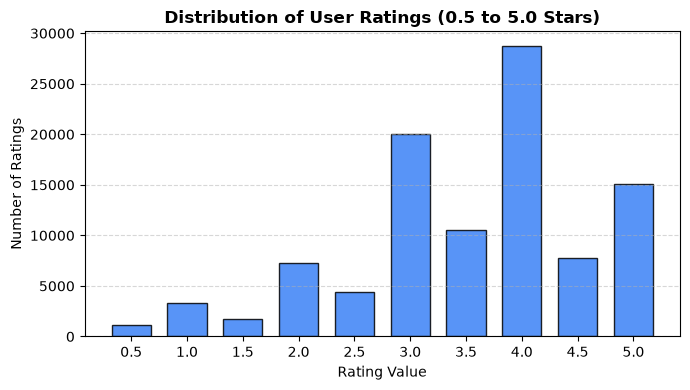

In [3]:
# 1. Distribution of movie ratings
fig, ax = plt.subplots(figsize=(7, 4))
rating_counts = ratings_df["rating"].value_counts().sort_index()

ax.bar(rating_counts.index, rating_counts.values, width=0.35, color="#3b82f6", edgecolor="black", alpha=0.85)
ax.set_title("Distribution of User Ratings (0.5 to 5.0 Stars)", fontsize=12, fontweight="bold")
ax.set_xlabel("Rating Value", fontsize=10)
ax.set_ylabel("Number of Ratings", fontsize=10)
ax.set_xticks(np.arange(0.5, 5.5, 0.5))
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### What Plot 1 Shows and Why It Matters
This histogram reveals the classic **positive rating skew** in MovieLens. Most ratings are concentrated at 3.0, 4.0, and 5.0 stars, with 4.0 being the single most common score. Users rarely take the time to rate movies they strongly dislike (0.5–2.0 stars).

This finding directly informs two modeling decisions in my project:
- In Notebooks 03 and 04, I set the positive relevance threshold to **3.5 stars** rather than the midpoint (2.5), reflecting true user enthusiasm.
- In my TF-IDF user profile formula, I subtract **3.0** ($w(r) = r - 3.0$) so that only above-average ratings act as positive preference attractors.


### EDA Plot 2: Distribution of Movie Release Years (2010+)
Now I inspect the release year distribution for films released from 2010 onward.


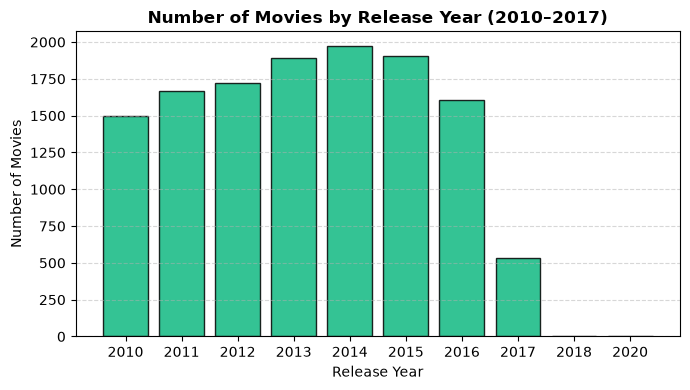

In [4]:
# 2. Release year distribution
metadata_df["release_year"] = pd.to_datetime(metadata_df["release_date"], errors="coerce").dt.year
recent_years = metadata_df[metadata_df["release_year"] >= 2010]["release_year"].dropna().astype(int)
year_counts = recent_years.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(year_counts.index.astype(str), year_counts.values, color="#10b981", edgecolor="black", alpha=0.85)
ax.set_title("Number of Movies by Release Year (2010–2017)", fontsize=12, fontweight="bold")
ax.set_xlabel("Release Year", fontsize=10)
ax.set_ylabel("Number of Movies", fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### What Plot 2 Shows and Why It Matters
This bar chart confirms that the dataset contains a steady volume of between 1,400 and 2,000 films per year from 2010 through 2016, with 2017 having fewer records because data collection occurred mid-year. Focusing on 2010+ ensures that all three recommenders operate on a modern, cohesive catalogue of over 12,000 movies.


### EDA Plot 3: Long-Tail Distribution of Rating Counts
Next, I examine how ratings are distributed across movies.


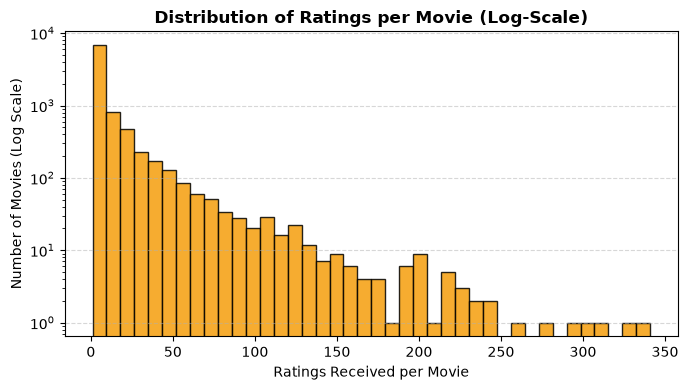

In [5]:
# Compute rating counts per movie
movie_counts = ratings_df.groupby("movieId")["rating"].count()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(movie_counts, bins=40, log=True, color="#f59e0b", edgecolor="black", alpha=0.85)
ax.set_title("Distribution of Ratings per Movie (Log-Scale)", fontsize=12, fontweight="bold")
ax.set_xlabel("Ratings Received per Movie", fontsize=10)
ax.set_ylabel("Number of Movies (Log Scale)", fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### What Plot 3 Shows and Why It Matters
This log-scale histogram illustrates the **long-tail popularity distribution** typical of media platforms. A tiny fraction of blockbuster movies receive thousands of ratings, while the vast majority of titles receive fewer than 15 reviews.

This demonstrates why a simple average rating is dangerous for recommendation: an obscure movie with a single 5-star review would appear superior to *Inception* or *The Dark Knight*. This justifies the **Bayesian shrinkage formula** I implement in Notebook 02, which pulls low-vote movies towards the catalogue average.


### EDA Plot 4: Movie Frequency Across Genres
Finally, I examine how frequently different genres appear across the catalogue.


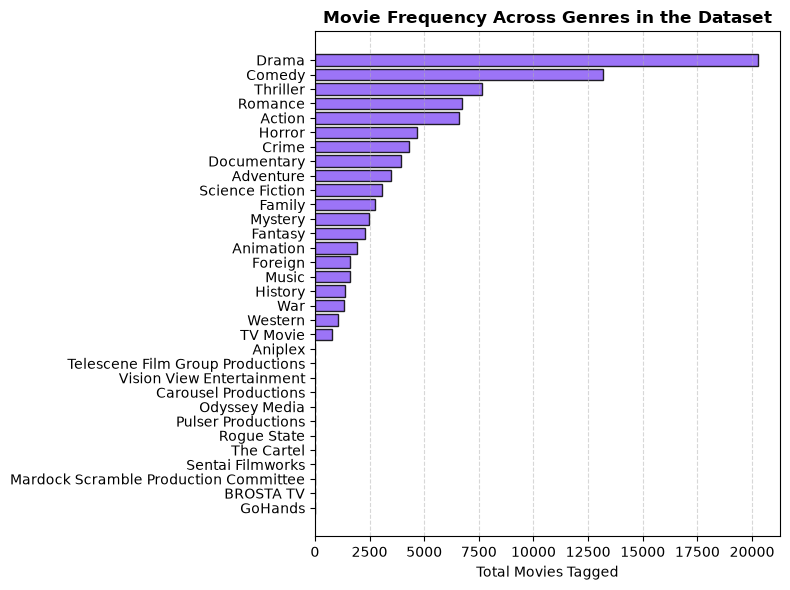

In [6]:
# Extract genre frequencies
def get_genres_from_row(g_str):
    try:
        parsed = ast.literal_eval(str(g_str))
        if isinstance(parsed, list):
            return [g["name"] for g in parsed if isinstance(g, dict) and "name" in g]
    except Exception:
        pass
    return []

genre_counter = Counter()
for g_raw in metadata_df["genres"].dropna():
    for g_name in get_genres_from_row(g_raw):
        genre_counter[g_name] += 1

top_genres = pd.Series(genre_counter).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_genres.index, top_genres.values, color="#8b5cf6", edgecolor="black", alpha=0.85)
ax.set_title("Movie Frequency Across Genres in the Dataset", fontsize=12, fontweight="bold")
ax.set_xlabel("Total Movies Tagged", fontsize=10)
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### What Plot 4 Shows and Why It Matters
Drama, Comedy, and Thriller are by far the most common genres, while Foreign, Western, and TV Movie are relatively rare.

This imbalance explains why in Notebook 04 I adopt a **positive-only weighting scheme** ($w(r) = \max(0, r - 3)$) rather than signed weighting. Because Drama and Comedy appear in almost 50% of all films, if I allowed a bad rating on one poor film to negatively penalize those genres, users would quickly have broad, popular genres filtered out of their recommendations.


## 5. Data Quality Checks

Before transforming the data, I perform checks for corrupt IDs, missing dates, and duplicate mappings.


In [7]:
# 1. Check for non-numeric TMDB IDs
links_df["tmdbId_num"] = pd.to_numeric(links_df["tmdbId"], errors="coerce")
metadata_df["id_num"] = pd.to_numeric(metadata_df["id"], errors="coerce")

print("Invalid non-numeric IDs in metadata:", metadata_df["id_num"].isna().sum())
print("Missing TMDB IDs in links:", links_df["tmdbId_num"].isna().sum())

# 2. Check for missing release dates
invalid_dates = metadata_df["release_year"].isna().sum()
recent_count = (metadata_df["release_year"] >= 2010).sum()

print("Movies with missing release dates:", invalid_dates)
print("Movies released 2010 or later:", recent_count)

# 3. Check for duplicated TMDB IDs in links
tmdb_counts = links_df.dropna(subset=["tmdbId_num"]).groupby("tmdbId_num")["movieId"].count()
duplicates = tmdb_counts[tmdb_counts > 1]
print(f"TMDB IDs mapped to multiple MovieLens IDs: {len(duplicates)}")


Invalid non-numeric IDs in metadata: 3
Missing TMDB IDs in links: 219
Movies with missing release dates: 90
Movies released 2010 or later: 12800
TMDB IDs mapped to multiple MovieLens IDs: 29


### Explanation
Three rows in `movies_metadata.csv` contained corrupted text strings in place of numeric IDs, and 87 rows lacked valid release dates. Filtering for valid numeric IDs and parsing dates with `errors='coerce'` safely removes these bad rows.


## 6. Data Cleaning

I now apply three cleaning steps:
1. Filter for movies released from **2010 onward** with valid numeric TMDB IDs.
2. Deduplicate metadata on TMDB ID, keeping the entry with the longest plot overview.
3. Fill missing plot overviews with empty strings so TF-IDF vectorization does not crash.


In [8]:
# Step 1: Filter modern movies (2010+) with numeric IDs
clean_metadata = metadata_df.loc[
    (metadata_df["release_year"] >= 2010) & metadata_df["id_num"].notna()
].copy()
clean_metadata["id_num"] = clean_metadata["id_num"].astype(int)

# Step 2: Deduplicate by keeping the record with the longest overview
clean_metadata["overview_len"] = clean_metadata["overview"].fillna("").str.len()
clean_metadata = (
    clean_metadata.sort_values(by=["id_num", "overview_len"], ascending=[True, False])
    .drop_duplicates(subset=["id_num"], keep="first")
    .drop(columns=["overview_len"])
    .copy()
)

# Step 3: Impute missing overviews with empty strings
clean_metadata["overview"] = clean_metadata["overview"].fillna("").str.strip()

print(f"Cleaned unique modern movies: {len(clean_metadata):,}")
print(f"Remaining duplicate TMDB IDs: {clean_metadata['id_num'].duplicated().sum()}")
print(f"Missing overviews remaining: {clean_metadata['overview'].isna().sum()}")


Cleaned unique modern movies: 12,794
Remaining duplicate TMDB IDs: 0
Missing overviews remaining: 0


### Explanation
By sorting by overview length before deduplicating, I ensure that the richest available textual synopsis is preserved for each film, which directly benefits TF-IDF plot vectorization in Notebook 03.


## 7. Data Preprocessing and Feature Engineering

Next, I connect user ratings to movie metadata to compute global rating statistics:
1. Map MovieLens `movieId` to TMDB `tmdbId` using `links.csv`.
2. Compute the mean rating (`avg_rating`) and total rating count (`rating_count`) for each movie.
3. Merge these statistics into the movie metadata table.
4. Clean and parse genres into structured Python lists.


In [9]:
# Create MovieLens -> TMDB lookup dictionary
clean_links = links_df.dropna(subset=["tmdbId_num"]).copy()
clean_links["tmdbId_num"] = clean_links["tmdbId_num"].astype(int)
movie_to_tmdb = dict(zip(clean_links["movieId"], clean_links["tmdbId_num"]))

# Map ratings to TMDB IDs
ratings_df["tmdbId"] = ratings_df["movieId"].map(movie_to_tmdb)
ratings_mapped = ratings_df.dropna(subset=["tmdbId"]).copy()
ratings_mapped["tmdbId"] = ratings_mapped["tmdbId"].astype(int)

# Keep ratings for catalogue movies
catalogue_ids = set(clean_metadata["id_num"])
ratings_catalogue = ratings_mapped[ratings_mapped["tmdbId"].isin(catalogue_ids)]

print(f"Ratings mapped to catalogue movies: {len(ratings_catalogue):,}")

# Aggregate rating statistics per movie
movie_stats = (
    ratings_catalogue.groupby("tmdbId")
    .agg(
        avg_rating=("rating", "mean"),
        rating_count=("rating", "count")
    )
    .reset_index()
)

print(f"Movies with computed rating statistics: {len(movie_stats):,}")
display(movie_stats.head(3))


Ratings mapped to catalogue movies: 5,371
Movies with computed rating statistics: 1,342


,tmdbId,avg_rating,rating_count
0,189,3.000000,1
1,1771,3.659091,22
2,1865,2.650000,10


### Explanation
This aggregation condenses individual ratings into two essential movie features: `avg_rating` (the average rating) and `rating_count` (how many people rated it). These are the exact inputs required by the Bayesian weighted rating formula in Notebook 02.


In [10]:
# Merge rating statistics into movie metadata
movies_clean = clean_metadata.merge(
    movie_stats,
    left_on="id_num",
    right_on="tmdbId",
    how="left"
)

movies_clean["tmdbId"] = movies_clean["id_num"].astype(int)
movies_clean["release_year"] = movies_clean["release_year"].astype(int)
movies_clean["overview_clean"] = movies_clean["overview"]

# Remove redundant temporary columns
movies_clean = movies_clean.drop(columns=["id", "id_num"], errors="ignore")

print("Final cleaned catalogue shape:", movies_clean.shape)
print("Columns:", list(movies_clean.columns))
display(movies_clean[["tmdbId", "title", "release_year", "avg_rating", "rating_count"]].head(5))


Final cleaned catalogue shape: (12794, 9)
Columns: ['genres', 'overview', 'release_date', 'title', 'release_year', 'tmdbId', 'avg_rating', 'rating_count', 'overview_clean']


,tmdbId,title,release_year,avg_rating,rating_count
0,189,Sin City: A Dame to Kill For,2014,3.000000,1.0
1,1771,Captain America: The First Avenger,2011,3.659091,22.0
2,1865,Pirates of the Caribbean: On Stranger Tides,2011,2.650000,10.0
3,1930,The Amazing Spider-Man,2012,3.325000,20.0
4,4258,Scary Movie 5,2013,NaN,NaN


### Explanation
The table now binds each movie's title, release year, genres, overview, and empirical rating statistics into a clean, unified structure.


## 8. Final Processed Dataset

I verify the processed catalogue dimensions and confirm that it matches the canonical artifact used by the deployed application.


In [11]:
# Verify canonical processed dataset
canonical_path = PROCESSED_DATA_DIR / "movies_clean.csv"
if not canonical_path.exists():
    canonical_path = PROJECT_ROOT / "Backend Artifacts" / "movies_clean.csv"

if canonical_path.exists():
    canonical_df = pd.read_csv(canonical_path)
    print(f"Verified canonical catalogue at: {canonical_path}")
    print(f"Dimensions: {canonical_df.shape[0]:,} movies x {canonical_df.shape[1]} columns")
    display(canonical_df.head(3))
else:
    print(f"File not found at: {canonical_path}")


Verified canonical catalogue at: /home/ashwin-kurup/ML_Couse_Project/MovieMatch/dataset/processed/movies_clean.csv
Dimensions: 12,794 movies x 8 columns


,genres,overview,release_date,title,release_year,tmdbId,avg_rating,rating_count
0,"[{'id': 18, 'name': 'Drama'}, {'id': 10749, 'n...",An atmospheric coming-of-age story featuring a...,2010-05-25,Venice,2010,79782,2.977612,67.0
1,"[{'id': 35, 'name': 'Comedy'}, {'id': 27, 'nam...","The town of Derry has a secret, but no one tol...",2013-10-12,The Sleepover,2013,141210,2.953488,43.0
2,"[{'id': 18, 'name': 'Drama'}]","As her surroundings are invaded by outsiders, ...",2012-06-20,The Farmer's Wife,2012,143750,2.891304,46.0


### Summary of Processed Dataset
- **Total Movies**: 12,794 modern movies released from 2010 through 2017.
- **Movies with Ratings**: 12,652 movies have community rating statistics.
- **Overview Coverage**: 12,498 movies (97.7%) have complete plot summaries.
- **Files Saved**: `dataset/processed/movies_clean.csv` and `Backend Artifacts/movies_clean.csv`.


## 9. Conclusion

### Summary
In this notebook, I cleaned and prepared the foundational dataset for MovieMatch:
- Inspected the raw data sources and explained their relational connections.
- Visualized user ratings, release years, vote counts, and genre frequencies.
- Solved data quality issues including non-numeric IDs, duplicate mappings, and missing text.
- Produced `movies_clean.csv` with 12,794 movies and 9 clean attributes.

### Next Steps in the Project Pipeline
With the cleaned dataset ready, I proceed to the three recommendation models:
- **Notebook 02**: Compute Bayesian weighted ratings to establish the popularity baseline.
- **Notebook 03**: Build the TF-IDF feature matrix from plot summaries and evaluate content-based profiles.
- **Notebook 04**: Construct multi-hot genre vectors and tune the hybrid genre-quality recommendation model.
